# YZ50 Hafta 9: Sıfırdan Tokenizer (Byte Pair Encoding)

Bu notebook **baştan sona tek parça** çalışır: `Runtime → Run all`. **GPU gerekmez** (normal CPU runtime yeterli). Toplam süre (veri indirme dahil) yaklaşık 1-3 dakikadır.

**İçindekiler**

| Bölüm | Ne yapıyoruz | Videoda |
|---|---|---|
| 0 | Kurulum, Türkçe veri (geçen haftaki hazırlık), ayarlar | – |
| Görev 1 | Metni byte'lara çevir: kod noktası, UTF-8, neden doğrudan vocab olmaz | 0:14:56 – 0:23:50 |
| Görev 2 | BPE'yi sıfırdan yaz, Türkçe metinde eğit, ilk 20 birleştirme, sıkıştırma oranı | 0:23:50 – 0:39:20 |
| Görev 3 | `encode` ve `decode`, geçersiz UTF-8 | 0:42:47 – 0:57:36 |
| Görev 4 | GPT-4'ün regex deseni, yeniden eğitim, kesme işaretli kelimeler | 0:57:36 – 1:11:38 |
| Görev 5 | Türkçe ile İngilizceyi GPT-4 tokenizer'ı (`tiktoken`) ve kendi tokenizer'ımızla karşılaştır | – |

**Telif notu:** Veri, geçen haftaki gibi Oğuz Atay'ın *Tutunamayanlar* romanıdır. Metin yalnızca bu ödevin eğitim amacıyla Colab içinde indirilir. **Metni veya türettiğin dosyaları GitHub'a yükleme.** Notebook'ta metinden alıntı gösterilmez; görünen yalnızca token parçaları ve sayılardır.

## 0. Kurulum, veri ve ayarlar

`regex` paketi, standart `re`'nin bilmediği `\p{L}` (herhangi bir dilden harf) gibi ifadeleri destekler; GPT-4'ün deseni bunu kullanır. `tiktoken` OpenAI'ın resmi tokenizer kütüphanesidir (Görev 5).

In [1]:
%pip install -q tiktoken regex

In [2]:
import re, time, unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import requests
import regex
import matplotlib.pyplot as plt
from IPython.display import display

HEDEF_KARAKTER = 1_115_394
ILK_YUZDE_ATLA = 3.0
SON_YUZDE_ATLA = 1.0
MIN_SAYI = 100

EGITIM_KARAKTER = 200_000
VOCAB_SIZE = 512
DEGERLENDIRME_KARAKTER = 30_000

print(f"Vocab hedefi: {VOCAB_SIZE}  ->  {VOCAB_SIZE - 256} birleştirme")
print(f"Tokenizer eğitim metni: ilk {EGITIM_KARAKTER:,} karakter".replace(",", "."))

Vocab hedefi: 512  ->  256 birleştirme
Tokenizer eğitim metni: ilk 200.000 karakter


**Ayarlar**

- `EGITIM_KARAKTER`: Tokenizer'ı eğiteceğimiz Türkçe metin uzunluğu. Saf Python ile yazdığımız BPE her birleştirmede metni baştan taradığı için tüm romanı kullanmak yavaş olur; 200 bin karakter hem hızlı hem yeterli.
- `VOCAB_SIZE`: Son sözlük boyutu. İlk 256 token ham byte'lardır, kalanı birleştirmelerdir. `512` → 256 birleştirme.
- `DEGERLENDIRME_KARAKTER`: Eğitimde görmediği metin üzerinde sıkıştırmayı ölçeceğimiz uzunluk.

**Veri.** Geçen hafta Görev 4'te hazırladığımız Türkçe veriyi aynı adımlarla yeniden üretiyoruz: indir → temizle (NFC, satır sonu tireleri, sayfa numaraları, paragraf birleştirme, tipografik işaretler) → baştan/sondan kırp → nadir karakterleri at. Bu hafta sözlük karakter değil **byte** olduğu için nadir karakter filtresi şart değil, ama aynı metinle çalışmak için bırakıyoruz.

In [3]:
URL = "https://dn760108.eu.archive.org/0/items/71467/71467_djvu.txt"
HEADERS = {"User-Agent": "YZ50-Hafta9-egitim-odevi/1.0 (ogrenci odevi)"}

print("İndiriliyor...")
yanit = requests.get(URL, headers=HEADERS, timeout=120)
yanit.raise_for_status()
HAM = yanit.content.decode("utf-8", errors="replace")
print(f"İndirildi: {len(HAM):,} karakter".replace(",", "."))

İndiriliyor...
İndirildi: 1.287.010 karakter


In [4]:
ESLEME = {
    "‘": "'", "’": "'", "´": "'", "`": "'",
    "“": '"', "”": '"', "«": '"', "»": '"', "„": '"',
    "–": "—", "…": "...", " ": " ", "\t": " ", "­": None,
    "î": "i", "Î": "İ", "û": "u", "Û": "U",
}
TABLO = str.maketrans(ESLEME)
HARF = "a-zçğıöşüâ"
CUMLE_SONU = ".!?…\"”»:"

def paragraflari_birlestir(t):
    satirlar = [s.strip() for s in t.split("\n")]
    uzun = sorted(len(s) for s in satirlar if len(s) > 20)
    genislik = uzun[int(len(uzun) * 0.9)] if uzun else 60
    paragraflar, cur, onceki = [], "", ""
    for s in satirlar:
        if not s:
            continue
        if cur:
            onceki_bitti = onceki[-1] in CUMLE_SONU
            kisa_satir = len(onceki) < 0.75 * genislik
            yeni_diyalog = s[0] in "—-" and onceki_bitti
            if (onceki_bitti and kisa_satir) or yeni_diyalog:
                paragraflar.append(cur)
                cur = s
            else:
                cur += " " + s
        else:
            cur = s
        onceki = s
    if cur:
        paragraflar.append(cur)
    return "\n".join(re.sub(r" {2,}", " ", p) for p in paragraflar)

def temizle(ham):
    t = unicodedata.normalize("NFC", ham).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(TABLO)
    t = re.sub(r"¬\s*", "", t)
    t = re.sub(rf"([{HARF}])-[ \t]*\n[ \t]*([{HARF}])", r"\1\2", t)
    satirlar = [s.strip() for s in t.split("\n")]
    sayac = Counter(s for s in satirlar if 0 < len(s) < 60)
    basliklar = {s for s, n in sayac.items() if n >= 12 and s[-1] not in CUMLE_SONU and s[0] not in "—-\"'("}
    temiz = []
    for s in satirlar:
        if s in basliklar:
            continue
        if re.fullmatch(r"[\W_]*\d{1,4}[\W_]*", s):
            continue
        if 0 < len(s) < 25 and sum(c.isalpha() for c in s) / len(s) < 0.4:
            continue
        temiz.append(s)
    return paragraflari_birlestir("\n".join(temiz))

TEMIZ = temizle(HAM)
bas = int(len(TEMIZ) * ILK_YUZDE_ATLA / 100)
bas = TEMIZ.find("\n", bas) + 1 if TEMIZ.find("\n", bas) != -1 else bas
son = int(len(TEMIZ) * (1 - SON_YUZDE_ATLA / 100))
KIRPIK = TEMIZ[bas:son]

kesim = KIRPIK[:HEDEF_KARAKTER]
son_satir = kesim.rfind("\n")
SECILEN = kesim[:son_satir] if son_satir > HEDEF_KARAKTER - 3000 else kesim

sayac = Counter(SECILEN)
atilan = {c for c, n in sayac.items() if n < MIN_SAYI and c != "\n"}
SECILEN = SECILEN.translate({ord(c): None for c in atilan})
SECILEN = re.sub(r" {2,}", " ", re.sub(r" ?\n ?", "\n", SECILEN)).strip()

n_tr = int(0.9 * len(SECILEN))
train_text, val_text = SECILEN[:n_tr], SECILEN[n_tr:]

display(pd.DataFrame({
    "Bilgi": ["Ham karakter", "Temizlik sonrası", "Veri setinde kullanılan", "Eğitim kısmı", "Doğrulama kısmı",
              "Farklı karakter", "UTF-8 byte sayısı (kullanılan)"],
    "Değer": [f"{len(HAM):,}".replace(",", "."), f"{len(TEMIZ):,}".replace(",", "."),
              f"{len(SECILEN):,}".replace(",", "."), f"{len(train_text):,}".replace(",", "."),
              f"{len(val_text):,}".replace(",", "."), len(set(SECILEN)),
              f"{len(SECILEN.encode('utf-8')):,}".replace(",", ".")],
}))

,Bilgi,Değer
0,Ham karakter,1.287.010
1,Temizlik sonrası,1.236.448
2,Veri setinde kullanılan,1.114.830
3,Eğitim kısmı,1.003.347
4,Doğrulama kısmı,111.483
5,Farklı karakter,71
6,UTF-8 byte sayısı (kullanılan),1.223.732


## Görev 1: Metni byte'lara çevir
*(Video 0:14:56 – 0:23:50)*

**Ne isteniyor?** Türkçe harfler içeren (`ç ğ ı ö ş ü`) bir cümle seç. Her harfin **Unicode kod noktasını** ve **UTF-8 byte'larını** yazdır. Hangi harfler 1 byte, hangileri 2 byte tutuyor? Kod noktalarını doğrudan vocab olarak kullanmak neden kötü bir fikir?

**Ne işe yarar?** Model metni değil **sayıları** görür. Önce "bir harf bilgisayarda hangi sayıya dönüşüyor" sorusunu cevaplamalıyız, çünkü BPE'nin başlangıç malzemesi bu sayılar.

- **Unicode kod noktası:** Her karaktere verilmiş numara (`ord('ç')` → 231).
- **UTF-8:** Bu numarayı diske/belleğe yazmanın yolu. Karaktere göre 1 ila 4 byte tutar. `a` gibi ASCII harfler 1 byte, `ç ğ ı ö ş ü` gibi harfler 2 byte.

In [5]:
cumle = "İstanbul'da ışıklı ağaçların gölgesinde çocuklar güzel şarkılar söyledi."

satirlar = []
for ch in dict.fromkeys(cumle):
    b = list(ch.encode("utf-8"))
    satirlar.append({
        "Karakter": repr(ch),
        "Kod noktası (ord)": ord(ch),
        "Unicode": f"U+{ord(ch):04X}",
        "UTF-8 byte'ları": b,
        "Byte sayısı": len(b),
    })
df_g1 = pd.DataFrame(satirlar)
print("GÖREV 1: Cümledeki her farklı karakter")
display(df_g1.style.hide(axis="index"))

bir = [r["Karakter"] for r in satirlar if r["Byte sayısı"] == 1]
iki = [r["Karakter"] for r in satirlar if r["Byte sayısı"] == 2]
print(f"\n1 byte tutanlar ({len(bir)} karakter): {' '.join(bir)}")
print(f"2 byte tutanlar ({len(iki)} karakter): {' '.join(iki)}")
print(f"\nCümle: {len(cumle)} karakter -> {len(cumle.encode('utf-8'))} byte")
print("Ham byte listesi:", list(cumle.encode("utf-8")))

GÖREV 1: Cümledeki her farklı karakter


Karakter,Kod noktası (ord),Unicode,UTF-8 byte'ları,Byte sayısı
'İ',304,U+0130,"[196, 176]",2
's',115,U+0073,[115],1
't',116,U+0074,[116],1
'a',97,U+0061,[97],1
'n',110,U+006E,[110],1
'b',98,U+0062,[98],1
'u',117,U+0075,[117],1
'l',108,U+006C,[108],1
"""'""",39,U+0027,[39],1
'd',100,U+0064,[100],1



1 byte tutanlar (20 karakter): 's' 't' 'a' 'n' 'b' 'u' 'l' "'" 'd' ' ' 'k' 'r' 'g' 'e' 'i' 'o' 'c' 'z' 'y' '.'
2 byte tutanlar (7 karakter): 'İ' 'ı' 'ş' 'ğ' 'ç' 'ö' 'ü'

Cümle: 72 karakter -> 86 byte
Ham byte listesi: [196, 176, 115, 116, 97, 110, 98, 117, 108, 39, 100, 97, 32, 196, 177, 197, 159, 196, 177, 107, 108, 196, 177, 32, 97, 196, 159, 97, 195, 167, 108, 97, 114, 196, 177, 110, 32, 103, 195, 182, 108, 103, 101, 115, 105, 110, 100, 101, 32, 195, 167, 111, 99, 117, 107, 108, 97, 114, 32, 103, 195, 188, 122, 101, 108, 32, 197, 159, 97, 114, 107, 196, 177, 108, 97, 114, 32, 115, 195, 182, 121, 108, 101, 100, 105, 46]


**Kod noktasını doğrudan vocab olarak kullansak ne olur?** Aşağıdaki tablo üç seçeneği yan yana koyar. Embedding tablosunun satır sayısı = vocab boyutu; her satır `n_embd` sayıdır (burada 256 alıyoruz, Hafta 8'deki büyük modelle aynı).

In [6]:
N_EMBD = 256
UNICODE_TANIMLI = 150_000
UNICODE_ARALIK = 0x10FFFF + 1

secenekler = [
    ("Kod noktası = token (tanımlı karakterler)", UNICODE_TANIMLI),
    ("Kod noktası = token (tüm aralık)", UNICODE_ARALIK),
    ("Ham UTF-8 byte'ları", 256),
    (f"BPE (bu notebook, {VOCAB_SIZE})", VOCAB_SIZE),
]
satirlar = [{"Seçenek": ad, "Vocab boyutu": v, "Embedding parametresi": v * N_EMBD,
             "Cümle uzunluğu (token)": len(cumle) if "Kod noktası" in ad else len(cumle.encode("utf-8")) if "byte" in ad else None}
            for ad, v in secenekler]
df_vocab = pd.DataFrame(satirlar)
print("Vocab seçeneklerinin karşılaştırması")
nokta = lambda v: f"{v:,.0f}".replace(",", ".")
display(df_vocab.style.hide(axis="index").format({"Vocab boyutu": nokta, "Embedding parametresi": nokta, "Cümle uzunluğu (token)": "{:.0f}"}, na_rep="–"))

olan = len(set(SECILEN))
print(f"\nBizim Türkçe verimizde gerçekten kullanılan farklı karakter: {olan}  (tanımlı {UNICODE_TANIMLI:,} karakterin yalnızca %{100 * olan / UNICODE_TANIMLI:.3f}'i)".replace(",", "."))

Vocab seçeneklerinin karşılaştırması


Seçenek,Vocab boyutu,Embedding parametresi,Cümle uzunluğu (token)
Kod noktası = token (tanımlı karakterler),150.000,38.400.000,72
Kod noktası = token (tüm aralık),1.114.112,285.212.672,72
Ham UTF-8 byte'ları,256,65.536,86
"BPE (bu notebook, 512)",512,131.072,–



Bizim Türkçe verimizde gerçekten kullanılan farklı karakter: 71  (tanımlı 150.000 karakterin yalnızca %0.047'i)


**Nasıl okunur?**
- Kod noktası vocab'ı **çok büyük**: yüz binlerce satır, bunların neredeyse hepsi bizim metinde hiç geçmiyor. Hiç görülmeyen bir satır eğitimde hiç güncellenmez (Hafta 8 videosundaki "ayrılmış ama hiç yazılmamış bellek" mantığı).
- Unicode standardı **yaşayan** bir standart: yeni sürümlerle karakter ekleniyor. Sözlüğü ona bağlamak sabit bir temsil vermez.
- Ham byte'lar vocab'ı **256**'ya indirir ama diziyi uzatır: aynı cümle `ç ğ ı ö ş ü` yüzünden karakter sayısından daha çok byte tutar. Dizi uzadıkça `block_size` içine az metin sığar. BPE bu ikisinin arasında bir denge kurar: byte'lardan başla, sık geçen ikilileri birleştirerek diziyi kısalt.

## Görev 2: BPE'yi sıfırdan yaz ve Türkçe metinde eğit
*(Video 0:23:50 – 0:39:20)*

**Ne isteniyor?** Geçen hafta derlediğin Türkçe metinde BPE eğit: ardışık ikilileri say, en sık geçeni yeni bir token'la birleştir, istediğin vocab boyutuna gelene kadar tekrarla. **İlk 20 birleştirmeyi metin olarak yazdır** (hangi harf grupları önce birleşiyor?) ve **sıkıştırma oranını** (byte sayısı / token sayısı) yaz.

**Ne işe yarar?** Karakter düzeyindeki modelin sorunu, dizinin çok uzun olması ve `block_size` penceresine az metin sığmasıydı. BPE, sık geçen harf gruplarını tek token yaparak aynı metni **daha kısa bir dizi** haline getirir.

**Algoritma (4 adım):**
1. Metni UTF-8 byte'larına çevir (başlangıç vocab'ı 0-255).
2. `get_stats`: bütün ardışık ikilileri say.
3. En sık ikiliyi seç, `merge` ile her yerde yeni bir id (256, 257, ...) ile değiştir.
4. Hedef vocab boyutuna ulaşana kadar 2-3'ü tekrarla; her birleştirmeyi `merges` sözlüğüne kaydet.

**Vocab boyutu = 256 + birleştirme sayısı.** `merges` sözlüğü tokenizer'ın öğrendiği her şeydir; ikinci parça olan `vocab`, her id'nin hangi byte'lara karşılık geldiğini tutar.

In [7]:
def get_stats(ids, sayac=None):
    sayac = {} if sayac is None else sayac
    for a, b in zip(ids, ids[1:]):
        sayac[(a, b)] = sayac.get((a, b), 0) + 1
    return sayac

def merge(ids, pair, idx):
    yeni, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and ids[i] == pair[0] and ids[i + 1] == pair[1]:
            yeni.append(idx)
            i += 2
        else:
            yeni.append(ids[i])
            i += 1
    return yeni

def vocab_olustur(merges):
    vocab = {i: bytes([i]) for i in range(256)}
    for (a, b), idx in merges.items():
        vocab[idx] = vocab[a] + vocab[b]
    return vocab

def egit(metin, vocab_size):
    ids = list(metin.encode("utf-8"))
    merges, uzunluk, sayilar = {}, [len(ids)], []
    for idx in range(256, vocab_size):
        stats = get_stats(ids)
        if not stats:
            break
        pair = max(stats, key=stats.get)
        ids = merge(ids, pair, idx)
        merges[pair] = idx
        sayilar.append(stats[pair])
        uzunluk.append(len(ids))
    return merges, vocab_olustur(merges), uzunluk, sayilar

def parca(b):
    try:
        return repr(b.decode("utf-8"))
    except UnicodeDecodeError:
        return "".join(f"\\x{x:02x}" for x in b)

print(merge([5, 6, 6, 7, 9, 1], (6, 7), 99))

[5, 6, 99, 9, 1]


`merge` küçük bir örnekle kontrol edildi: `[5, 6, 6, 7, 9, 1]` içinde `(6, 7)` ikilisi `99` olmalı → `[5, 6, 99, 9, 1]`. Şimdi Türkçe metinde eğitiyoruz.

In [8]:
egitim_metni = train_text[:EGITIM_KARAKTER]
t0 = time.time()
merges, vocab, uzunluk, sayilar = egit(egitim_metni, VOCAB_SIZE)
sure = time.time() - t0

print(f"Eğitim metni: {len(egitim_metni):,} karakter, {uzunluk[0]:,} byte".replace(",", "."))
print(f"Yapılan birleştirme: {len(merges)}  |  Son vocab boyutu: {256 + len(merges)}  |  Süre: {sure:.0f} sn")
print(f"Başlangıç: {uzunluk[0]:,} token  ->  Sonuç: {uzunluk[-1]:,} token".replace(",", "."))
print(f"Sıkıştırma oranı (byte / token): {uzunluk[0] / uzunluk[-1]:.3f}")

Eğitim metni: 200.000 karakter. 219.160 byte
Yapılan birleştirme: 256  |  Son vocab boyutu: 512  |  Süre: 27 sn
Başlangıç: 219.160 token  ->  Sonuç: 102.684 token
Sıkıştırma oranı (byte / token): 2.134


In [9]:
satirlar = []
for i, ((a, b), idx) in enumerate(list(merges.items())[:20]):
    satirlar.append({
        "Sıra": i + 1,
        "Birleşen ikili": f"{parca(vocab[a])} + {parca(vocab[b])}",
        "Yeni token": parca(vocab[idx]),
        "Token id": idx,
        "Kaç kez geçti": sayilar[i],
    })
df_ilk20 = pd.DataFrame(satirlar)
print("GÖREV 2: İlk 20 birleştirme (metin olarak)")
display(df_ilk20.style.hide(axis="index"))

GÖREV 2: İlk 20 birleştirme (metin olarak)


Sıra,Birleşen ikili,Yeni token,Token id,Kaç kez geçti
1,\xc4 + \xb1,'ı',256,8454
2,'n' + ' ','n ',257,3504
3,\xc3 + \xbc,'ü',258,3165
4,'a' + 'r','ar',259,2868
5,'e' + ' ','e ',260,2834
6,\xc5 + \x9f,'ş',261,2654
7,'a' + ' ','a ',262,2424
8,'e' + 'r','er',263,2356
9,'i' + ' ','i ',264,2191
10,"',' + ' '","', '",265,2115


**Nasıl okunur?**
- **Birleşen ikili** sütunu `+` ile iki parçayı gösterir; **Yeni token** ikisinin birleşmiş hali. Boşluk `' '` olarak görünür.
- `\xc4` gibi gösterimler, tek başına geçerli bir karakter olmayan **yarım UTF-8 byte'ı** demektir (onaltılık yazılmış). Türkçe harfler 2 byte olduğu için ilk birleşmelerin bir kısmı `ı`, `ü`, `ş`, `ğ`, `ç` gibi harfleri **byte çiftlerinden yeniden kurar**; Görev 1'de gördüğümüz 2 byte'lık harflerin BPE'ye yansıması budur. Tabloda yarım byte'larla başlayan satırlar bunlardır.
- Sonraki birleşmeler sık harf çiftleri, ek parçaları ve boşluklu kelime başları/sonlarıdır. Hangi grupların (ek, hece, boşluklu başlangıç) önce çıktığına bakıp yorumla.
- **Kaç kez geçti** sütunu her adımda azalır; sonraki birleşmeler daha nadir kalıpları yakalar.

Sıkıştırma oranı vocab büyüdükçe nasıl değişiyor?


Birleştirme,Vocab boyutu,Token sayısı,Sıkıştırma (byte/token)
0,256,"219,160",1.000
20,276,"170,642",1.284
50,306,"144,868",1.513
100,356,"126,113",1.738
200,456,"108,744",2.015
256,512,"102,684",2.134


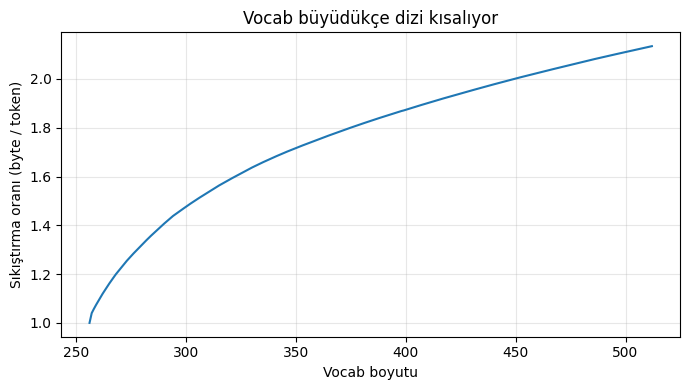

En uzun 15 token: 'ütün '  'ların '  'ını '  'Turgut'  'ları '  'ların'  'için '  'mış '  'kadar '  'ında '  'Selim'  'ğı '  'için'  'mış'  'gibi '


In [10]:
kontrol = sorted({0, 20, 50, 100, 200, len(merges)} & set(range(len(merges) + 1)))
satirlar = [{"Birleştirme": k, "Vocab boyutu": 256 + k, "Token sayısı": uzunluk[k],
             "Sıkıştırma (byte/token)": uzunluk[0] / uzunluk[k]} for k in kontrol]
df_sik = pd.DataFrame(satirlar)
print("Sıkıştırma oranı vocab büyüdükçe nasıl değişiyor?")
display(df_sik.style.hide(axis="index").format({"Token sayısı": "{:,.0f}", "Sıkıştırma (byte/token)": "{:.3f}"}))

plt.figure(figsize=(7, 4))
plt.plot([256 + k for k in range(len(uzunluk))], [uzunluk[0] / u for u in uzunluk])
plt.xlabel("Vocab boyutu"); plt.ylabel("Sıkıştırma oranı (byte / token)")
plt.title("Vocab büyüdükçe dizi kısalıyor")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

en_uzun = sorted(((i, b) for i, b in vocab.items() if i >= 256), key=lambda kv: (-len(kv[1]), kv[0]))[:15]
print("En uzun 15 token:", "  ".join(parca(b) for _, b in en_uzun))

**Nasıl okunur?**
- **Sıkıştırma oranı** 1.0'dan başlar (her byte bir token). Vocab büyüdükçe artar: aynı metin daha az token ile ifade edilir, yani `block_size` penceresine daha çok metin sığar.
- Eğri düzleşir: ilk birleşmeler büyük kazanç getirir, sonrakilerin kazancı küçülür. Vocab'ı sonsuza kadar büyütmek mantıklı değil; embedding tablosu ve çıkış katmanı büyür, nadir token'lar az eğitilir (videoda anlatılan denge).
- **En uzun token'lar** Türkçe kelime ve ek kalıplarını gösterir.

## Görev 3: `encode` ve `decode`
*(Video 0:42:47 – 0:57:36)*

**Ne isteniyor?** `decode(encode(metin))` metnin kendisini vermeli; **Türkçe karakterli ve emoji içeren** bir örnekle göster. Bazı token dizileri geçerli UTF-8 değil: `decode` bu durumda ne yapmalı, neden?

**Ne işe yarar?** Tokenizer eğitildikten sonra iki yönlü bir çevirmendir: **metin → token** (modele vermek için) ve **token → metin** (modelin ürettiğini okumak için). İkisinin tutarlı olması şart.

- **`decode`:** Her id'yi `vocab` ile byte'larına çevir, hepsini art arda yapıştır, sonunda UTF-8 olarak oku.
- **`encode`:** Metni byte'lara çevir, sonra `merges`'i **eğitimdeki sırayla** uygula: her turda ikililer arasında en erken birleşeni seç. Yeni token'lar eskilerin üstüne kurulduğu için sıra önemli.
- **Kenar durumu:** 0 ya da 1 byte'lık metinde ikili yoktur; döngü `len(ids) >= 2` ile durur.

In [11]:
def decode(ids, vocab):
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")

def encode(metin, merges):
    ids = list(metin.encode("utf-8"))
    while len(ids) >= 2:
        stats = get_stats(ids)
        pair = min(stats, key=lambda p: merges.get(p, float("inf")))
        if pair not in merges:
            break
        ids = merge(ids, pair, merges[pair])
    return ids

print(encode("", merges), encode("a", merges), decode(encode("ağ", merges), vocab))

[] [97] ağ


In [12]:
ornek = "Merhaba dünya! Çok güzel bir gün 😀 şimdi çıkıyoruz."
ids = encode(ornek, merges)
geri = decode(ids, vocab)

print("GÖREV 3: Örnek (Türkçe karakterler + emoji)")
print("Orijinal :", ornek)
print("Token id :", ids)
print("Parçalar :", "  ".join(parca(vocab[i]) for i in ids))
print("Geri     :", geri)
print("Aynı mı  :", geri == ornek)
print(f"\nEmoji: {len('😀')} karakter, {len('😀'.encode('utf-8'))} byte, {len(encode('😀', merges))} token")

testler = {
    "Örnek cümle (emoji'li)": ornek,
    "Eğitim metninden 5000 karakter": train_text[:5000],
    "Doğrulama metninden 5000 karakter (tokenizer görmedi)": val_text[:5000],
}
satirlar = []
for ad, m in testler.items():
    t = encode(m, merges)
    satirlar.append({"Metin": ad, "Karakter": len(m), "Byte": len(m.encode("utf-8")), "Token": len(t),
                     "byte/token": len(m.encode("utf-8")) / len(t), "decode(encode(x)) == x": decode(t, vocab) == m})
df_g3 = pd.DataFrame(satirlar)
display(df_g3.style.hide(axis="index").format({"byte/token": "{:.3f}"}))

GÖREV 3: Örnek (Türkçe karakterler + emoji)
Orijinal : Merhaba dünya! Çok güzel bir gün 😀 şimdi çıkıyoruz.
Token id : [77, 263, 329, 98, 262, 100, 308, 285, 33, 32, 195, 135, 111, 274, 103, 391, 276, 32, 291, 103, 373, 240, 159, 152, 128, 32, 261, 282, 441, 416, 375, 294, 425, 46]
Parçalar : 'M'  'er'  'ha'  'b'  'a '  'd'  'ün'  'ya'  '!'  ' '  \xc3  \x87  'o'  'k '  'g'  'üz'  'el'  ' '  'bir '  'g'  'ün '  \xf0  \x9f  \x98  \x80  ' '  'ş'  'im'  'di '  'çı'  'kı'  'yor'  'uz'  '.'
Geri     : Merhaba dünya! Çok güzel bir gün 😀 şimdi çıkıyoruz.
Aynı mı  : True

Emoji: 1 karakter, 4 byte, 4 token


Metin,Karakter,Byte,Token,byte/token,decode(encode(x)) == x
Örnek cümle (emoji'li),51,62,34,1.824,True
Eğitim metninden 5000 karakter,5000,5523,2446,2.258,True
Doğrulama metninden 5000 karakter (tokenizer görmedi),5000,5442,2531,2.150,True


**Nasıl okunur?**
- Emoji tek karakterdir ama **4 byte** tutar; eğittiğimiz metinde hiç geçmediği için büyük ölçüde birleşmeden, byte byte token olarak kalır (kaç token olduğu yukarıdaki satırda yazıyor). Tokenizer hiç görmediği bir karakteri bile işleyebilir, çünkü her şeyin altında 256 byte vardır.
- Üçüncü satır tokenizer'ın **görmediği** metindir; yine de geri çevrilebilir. Sıkıştırma oranı eğitim metninden biraz düşük çıkması normaldir.

**Her token dizisi geçerli metin değildir.** UTF-8'in bir kuralı var: çok byte'lı bir karakter özel bir kalıpla başlar. `128` (`10000000`) bir karakterin **başlangıcı** olamaz, yalnızca devamı olabilir. Dizi ortadan kesilirse ya da model rastgele bir token üretirse bozuk byte dizisi çıkar. Aşağıda görelim:

In [13]:
def strict(b):
    try:
        return repr(b.decode("utf-8"))
    except UnicodeDecodeError as e:
        return f"HATA: {e.reason}"

denemeler = [("a", [97]), ("ğ (tam)", [196, 159]), ("ğ'nin yarısı", [196]), ("tek başına 128", [128]), ("ç (tam)", [195, 167])]
satirlar = []
for ad, dizi in denemeler:
    b = bytes(dizi)
    satirlar.append({
        "Durum": ad,
        "Token id'leri": dizi,
        "İkilik": " ".join(format(x, "08b") for x in dizi),
        "Strict decode": strict(b),
        "errors='replace'": repr(decode(dizi, vocab)),
    })
df_utf = pd.DataFrame(satirlar)
print("Geçersiz UTF-8 örnekleri")
display(df_utf.style.hide(axis="index"))

Geçersiz UTF-8 örnekleri


Durum,Token id'leri,İkilik,Strict decode,errors='replace'
a,[97],01100001,'a','a'
ğ (tam),"[196, 159]",11000100 10011111,'ğ','ğ'
ğ'nin yarısı,[196],11000100,HATA: unexpected end of data,'�'
tek başına 128,[128],10000000,HATA: invalid start byte,'�'
ç (tam),"[195, 167]",11000011 10100111,'ç','ç'


**Cevap: `decode` ne yapmalı, neden?**

`bytes.decode` varsayılan olarak `errors="strict"` ile çalışır ve geçersiz byte dizisinde **hata verip programı durdurur**. Dil modeli ise token'ları kendisi seçer ve bozuk bir dizi üretebilir; bu durumda bütün çıktıyı kaybetmek istemeyiz. Bu yüzden `errors="replace"` kullanırız: bozuk yeri `�` (replacement character) ile değiştirir, gerisini okur. OpenAI'ın kodu da böyle yapar. Çıktıda `�` görmek, modelin geçersiz bir byte dizisi ürettiği anlamına gelir.

Not: `decode(encode(x)) == x` her zaman doğrudur; **ters yön** (`encode(decode(ids)) == ids`) her zaman doğru değildir, çünkü her id dizisi geçerli bir metin değildir.

## Görev 4: GPT-4'ün regex deseni
*(Video 0:57:36 – 1:11:38)*

**Ne isteniyor?** Metni önce GPT-4'ün desenle parçalara böl, BPE'yi **her parçada ayrı** çalıştır. Tokenizer'ı yeniden eğit ve birleştirmeleri öncekiyle karşılaştır. Sonra `Ankara'dan` ve `İstanbul'da` gibi kesme işaretli kelimeleri bu desenle böl. Desen İngilizce için yazılmış: **Türkçede ne yapıyor?**

**Ne işe yarar?** Saf BPE'de `dog.`, `dog!`, `dog?` gibi kelime + noktalama karışımları tek token olabilir; kelime ile noktalama birbirine karışır. Desen metni önce kutulara ayırır (harf grubu, rakam grubu, noktalama, boşluk). BPE her kutunun **içinde** çalışır, kutular arasında birleştirme yapmaz.

**Desenin parçaları (soldan sağa denenir):**

| Parça | Ne yakalar |
|---|---|
| `'(?i:[sdmt]\|ll\|ve\|re)` | İngilizce kısaltmalar: `'s 'd 'm 't 'll 've 're` (büyük/küçük harf fark etmez) |
| `[^\r\n\p{L}\p{N}]?+\p{L}+` | Başında en fazla bir boşluk/işaret olan harf yığını (`\p{L}` = herhangi bir dilden harf) |
| `\p{N}{1,3}` | En fazla 3 haneli rakam grubu |
| ` ?[^\s\p{L}\p{N}]++[\r\n]*` | Noktalama ve semboller |
| `\s*[\r\n]` , `\s+(?!\S)` , `\s+` | Satır sonları ve boşluklar |

In [14]:
GPT4_DESEN = r"""'(?i:[sdmt]|ll|ve|re)|[^\r\n\p{L}\p{N}]?+\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]++[\r\n]*|\s*[\r\n]|\s+(?!\S)|\s+"""

def bol(metin, desen=GPT4_DESEN):
    return regex.findall(desen, metin)

def goster(p):
    return p.replace(" ", "␣").replace("\n", "↵")

kelimeler = ["Ankara'dan", "İstanbul'da", "Ankara'ya", "İzmir'e", "Türkiye'nin", "Ali'ye", "Mehmet'in", "Ayşe'de", "Selim'dir", "Ankara’dan"]
satirlar = []
for k in kelimeler:
    p = bol(k)
    satirlar.append({"Kelime": k, "GPT-4 deseniyle parçalar": "  |  ".join(goster(x) for x in p), "Parça sayısı": len(p)})
df_kesme = pd.DataFrame(satirlar)
print("GÖREV 4: Kesme işaretli kelimeler desenle nasıl bölünüyor?")
display(df_kesme.style.hide(axis="index"))

cumle2 = "Ankara'dan geldim, İstanbul'da 12345 kitap okudum!"
print("\nCümle:", cumle2)
print("Parçalar:", [goster(x) for x in bol(cumle2)])

GÖREV 4: Kesme işaretli kelimeler desenle nasıl bölünüyor?


Kelime,GPT-4 deseniyle parçalar,Parça sayısı
Ankara'dan,Ankara | 'd | an,3
İstanbul'da,İstanbul | 'd | a,3
Ankara'ya,Ankara | 'ya,2
İzmir'e,İzmir | 'e,2
Türkiye'nin,Türkiye | 'nin,2
Ali'ye,Ali | 'ye,2
Mehmet'in,Mehmet | 'in,2
Ayşe'de,Ayşe | 'd | e,3
Selim'dir,Selim | 'd | ir,3
Ankara’dan,Ankara | ’dan,2



Cümle: Ankara'dan geldim, İstanbul'da 12345 kitap okudum!
Parçalar: ['Ankara', "'d", 'an', '␣geldim', ',', '␣İstanbul', "'d", 'a', '␣', '123', '45', '␣kitap', '␣okudum', '!']


**Nasıl okunur?**
- `\p{L}` herhangi bir dilden harfi yakaladığı için `ç ğ ı ö ş ü İ` **harf sayılır**; Türkçe kelimeler ortadan bölünmez. Bu, desenin Türkçede çalışan tarafı.
- Desenin ilk parçası İngilizce kısaltmalar için yazıldı (`'s 'd 'm 't 'll 've 're`). Türkçe ekler de kesme işaretinden sonra gelir; **bazıları kazara bir İngilizce kısaltmayla aynı harfle başlar**. Örneğin `'dan` ve `'da` için desen `'d` kısmını kısaltma sanıp ayırır, geri kalan `an` / `a` ayrı parça olur. `'ya`, `'e`, `'nin` gibi ekler ise hiçbir kısaltmayla eşleşmediği için kesme işaretiyle birlikte tek parça kalır. Yani **aynı yapı, ekin ilk harfine göre farklı bölünüyor**.
- Son satırdaki `’` (kıvrık kesme işareti) düz `'` olmadığı için kısaltma kuralına hiç girmez. Geçen haftaki temizlikte bunu düz `'`'ye çevirmiştik.
- Rakamlar en fazla 3'lü gruplanır (`12345` → `123` + `45`).

**Regex'li eğitim.** Metni desenle parçalara böl, her parçayı kendi byte listesine çevir ve BPE'yi bu parçalar üzerinde çalıştır. İkililer yalnızca **parçanın içinde** sayılır. Aynı parçalar (`' bir'` gibi) metinde çok kez geçtiği için her farklı parçayı bir kez tutup tekrar sayısıyla çarpıyoruz; sonuç aynı, ama çok daha hızlı.

In [15]:
def egit_regex(metin, vocab_size, desen=GPT4_DESEN):
    sayac_parca = Counter(regex.findall(desen, metin))
    parcalar = [list(p.encode("utf-8")) for p in sayac_parca]
    agirlik = list(sayac_parca.values())
    merges = {}
    uzunluk = [sum(len(p) * w for p, w in zip(parcalar, agirlik))]
    sayilar = []
    for idx in range(256, vocab_size):
        stats = {}
        for p, w in zip(parcalar, agirlik):
            for a, b in zip(p, p[1:]):
                stats[(a, b)] = stats.get((a, b), 0) + w
        if not stats:
            break
        pair = max(stats, key=stats.get)
        parcalar = [merge(p, pair, idx) for p in parcalar]
        merges[pair] = idx
        sayilar.append(stats[pair])
        uzunluk.append(sum(len(p) * w for p, w in zip(parcalar, agirlik)))
    return merges, vocab_olustur(merges), uzunluk, sayilar

def encode_regex(metin, merges, desen=GPT4_DESEN):
    ids = []
    for p in regex.findall(desen, metin):
        ids.extend(encode(p, merges))
    return ids

t0 = time.time()
merges_r, vocab_r, uzunluk_r, sayilar_r = egit_regex(egitim_metni, VOCAB_SIZE)
print(f"Regex'li eğitim bitti: {len(merges_r)} birleştirme, {time.time() - t0:.0f} sn")
print(f"Parça sayısı: {len(bol(egitim_metni)):,}  |  farklı parça: {len(set(bol(egitim_metni))):,}".replace(",", "."))

Regex'li eğitim bitti: 256 birleştirme, 13 sn
Parça sayısı: 33.596  |  farklı parça: 11.831


In [16]:
satirlar = []
liste_p, liste_r = list(merges.items())[:20], list(merges_r.items())[:20]
for i in range(20):
    (a, b), idx = liste_p[i]
    (a2, b2), idx2 = liste_r[i]
    satirlar.append({"Sıra": i + 1,
                     "Regex'siz yeni token": parca(vocab[idx]),
                     "Regex'li yeni token": parca(vocab_r[idx2]),
                     "Aynı mı": vocab[idx] == vocab_r[idx2]})
df_ilk20_kars = pd.DataFrame(satirlar)
print("GÖREV 4: İlk 20 birleştirme, regex'siz ve regex'li")
display(df_ilk20_kars.style.hide(axis="index"))

ortak_20 = len({vocab[i] for _, i in liste_p} & {vocab_r[i] for _, i in liste_r})
ortak_hepsi = len({vocab[i] for i in vocab if i >= 256} & {vocab_r[i] for i in vocab_r if i >= 256})
print(f"\nİlk 20'de ortak token: {ortak_20}/20   |   tüm {len(merges)} birleştirmede ortak token: {ortak_hepsi}/{len(merges)}")

GÖREV 4: İlk 20 birleştirme, regex'siz ve regex'li


Sıra,Regex'siz yeni token,Regex'li yeni token,Aynı mı
1,'ı','ı',True
2,'n ',' b',False
3,'ü','ü',True
4,'ar','ar',True
5,'e ','ş',False
6,'ş','an',False
7,'a ','er',False
8,'er','in',False
9,'i ','en',False
10,"', '",' d',False



İlk 20'de ortak token: 12/20   |   tüm 256 birleştirmede ortak token: 102/256


In [17]:
def sinir_asan(v):
    n = 0
    for i, b in v.items():
        if i < 256:
            continue
        s = b.decode("utf-8", errors="ignore")
        s = s[1:] if s.startswith(" ") else s
        harf = any(c.isalpha() for c in s)
        diger = any((not c.isalpha()) for c in s)
        if harf and diger:
            n += 1
    return n

deger_metni = val_text[:DEGERLENDIRME_KARAKTER]
egitim_ornek = egitim_metni[:DEGERLENDIRME_KARAKTER]
byte_egitim, byte_deger = len(egitim_ornek.encode("utf-8")), len(deger_metni.encode("utf-8"))
t_p_e, t_p_d = len(encode(egitim_ornek, merges)), len(encode(deger_metni, merges))
t_r_e, t_r_d = len(encode_regex(egitim_ornek, merges_r)), len(encode_regex(deger_metni, merges_r))

df_g4 = pd.DataFrame([
    {"Tokenizer": "Regex'siz BPE", "Vocab": 256 + len(merges), "Eğitim metni byte/token": byte_egitim / t_p_e,
     "Görülmemiş metin byte/token": byte_deger / t_p_d, "Harf + harf-dışı karışık token": sinir_asan(vocab)},
    {"Tokenizer": "Regex'li BPE (GPT-4 deseni)", "Vocab": 256 + len(merges_r), "Eğitim metni byte/token": byte_egitim / t_r_e,
     "Görülmemiş metin byte/token": byte_deger / t_r_d, "Harf + harf-dışı karışık token": sinir_asan(vocab_r)},
])
print("GÖREV 4: Regex'siz ve regex'li tokenizer karşılaştırması")
display(df_g4.style.hide(axis="index").format({"Eğitim metni byte/token": "{:.3f}", "Görülmemiş metin byte/token": "{:.3f}"}))

for k in ["Ankara'dan geldim", "İstanbul'da okudum"]:
    print(f"\n{k!r}")
    print("  Regex'siz:", "  ".join(parca(vocab[i]) for i in encode(k, merges)))
    print("  Regex'li :", "  ".join(parca(vocab_r[i]) for i in encode_regex(k, merges_r)))

GÖREV 4: Regex'siz ve regex'li tokenizer karşılaştırması


Tokenizer,Vocab,Eğitim metni byte/token,Görülmemiş metin byte/token,Harf + harf-dışı karışık token
Regex'siz BPE,512,2.230,2.174,78
Regex'li BPE (GPT-4 deseni),512,2.240,2.182,0



"Ankara'dan geldim"
  Regex'siz: 'A'  'n'  'kar'  'a'  "'"  'dan '  'gel'  'd'  'im'
  Regex'li : 'A'  'n'  'k'  'ar'  'a'  "'"  'd'  'an'  ' gel'  'd'  'im'

"İstanbul'da okudum"
  Regex'siz: 'İ'  'st'  'an'  'b'  'ul'  "'"  'da '  'ok'  'u'  'du'  'm'
  Regex'li : 'İ'  'st'  'an'  'b'  'ul'  "'"  'd'  'a'  ' ok'  'u'  'du'  'm'


**Nasıl okunur?**
- **Sıkıştırma:** İki oran birbirine çok yakın. Regex kutu sınırlarını aşan birleştirmelere izin vermediği için sıkıştırmanın düşmesi beklenebilirdi; bu küçük vocab'da düşmedi (fark ihmal edilebilir, bu veride regex'li hafifçe yüksek). Yani bu denemede regex'in sıkıştırma bedeli yok; kazanç token'ların daha temiz olması.
- **Harf + harf-dışı karışık token** sütunu, baştaki tek boşluk hariç, harf ile harf olmayan bir karakterin (boşluk, noktalama, kesme işareti) aynı token içinde bulunduğu token'ları sayar. Regex'siz tokenizer'da `'n '`, `', '`, `'. '` gibi kelime/cümle sonu + boşluk token'ları bu sayıyı yükseltir; regex'li tokenizer'da bu tür token oluşamaz.
- **İlk 20 birleştirme** iki tokenizer'da kısmen aynı, kısmen farklıdır. Fark şuradan gelir: regex'siz sürümde **kelime sonu + boşluk** token'ları (`'n '`, `'e '`, `'a '`, `', '`) çıkar; regex'li sürümde boşluk her zaman **sonraki kelimenin başına** yapışık olduğu için **boşluk + harf** token'ları (`' b'`, `' d'`, `' k'` gibi) çıkar. Tabloda iki sütunu karşılaştırarak bunu gör.
- Alttaki iki cümlede kesme işaretli kelimenin iki tokenizer'da nasıl bölündüğünü yan yana görebilirsin.

## Görev 5: Türkçe ile İngilizceyi karşılaştır
*(E-postada video aralığı yok)*

**Ne isteniyor?** Aynı paragrafın Türkçesini ve İngilizcesini GPT-4'ün tokenizer'ıyla (`tiktoken`, `cl100k_base`) token'la, **kelime başına kaç token** düştüğünü yaz. Sonra aynı Türkçe paragrafı **kendi tokenizer'ınla** token'la. Türkçenin eklemeli yapısı sayıları nasıl etkiliyor?

**Ne işe yarar?** Model metni token olarak okur; aynı anlam daha çok token ile ifade ediliyorsa pencereye (bağlama) daha az içerik sığar ve her adım daha pahalıdır. Videodaki örnek: İngilizce "hello how are you" 5 token, Korece karşılığı 15 token.

**Eklemeli yapı:** Türkçede anlam, köke eklenen eklerle kurulur (`kütüphane-ye`, `şehir-ler-i-nin`, `arkadaş-lar-ımız-la`). Tek bir Türkçe kelime, İngilizcede birkaç kelimelik bir ifadeye denk gelir. Bu yüzden Türkçede **kelime başına** token sayısı yüksek çıkabilir; ama **aynı anlam için** toplam token sayısına da bakmak gerekir.

In [18]:
import tiktoken

gpt4 = tiktoken.get_encoding("cl100k_base")

EN = ("Yesterday we went to the library after school. The librarian showed us a new book about the history of "
      "Anatolian cities. We read for two hours and took notes about the old trade routes. When we left, the streets "
      "were already full of people walking home from work. My friends decided to eat dinner near the harbor, "
      "so we took the ferry across the city.")
TR = ("Dün okuldan sonra kütüphaneye gittik. Kütüphaneci bize Anadolu şehirlerinin tarihi hakkında yeni bir kitap "
      "gösterdi. İki saat boyunca okuduk ve eski ticaret yolları hakkında notlar aldık. Ayrıldığımızda sokaklar işten "
      "eve yürüyen insanlarla çoktan dolmuştu. Arkadaşlarım akşam yemeğini limanın yakınında yemeye karar verdi, "
      "biz de vapurla şehrin karşı yakasına geçtik.")

kontrol_metinleri = [TR, EN, cumle2] + kelimeler
ayni_bolunme = all(regex.findall(gpt4._pat_str, m) == bol(m) for m in kontrol_metinleri)
print("Kendi desenimiz tiktoken'ın cl100k desenini aynı şekilde bölüyor mu:", ayni_bolunme)
print("cl100k_base vocab boyutu:", gpt4.n_vocab)

def satir(ad, metin, tokenlar):
    kelime = len(metin.split())
    return {"Metin / Tokenizer": ad, "Karakter": len(metin), "Byte": len(metin.encode("utf-8")), "Kelime": kelime,
            "Token": tokenlar, "Token / kelime": tokenlar / kelime, "Byte / token": len(metin.encode("utf-8")) / tokenlar}

satirlar = [
    satir("İngilizce - GPT-4", EN, len(gpt4.encode(EN))),
    satir("Türkçe - GPT-4", TR, len(gpt4.encode(TR))),
    satir("Türkçe - kendi tokenizer'ım (regex'siz)", TR, len(encode(TR, merges))),
    satir("Türkçe - kendi tokenizer'ım (regex'li)", TR, len(encode_regex(TR, merges_r))),
    satir("İngilizce - kendi tokenizer'ım (regex'li)", EN, len(encode_regex(EN, merges_r))),
]
df_g5 = pd.DataFrame(satirlar)
print("\nGÖREV 5: Token sayıları")
display(df_g5.style.hide(axis="index").format({"Token / kelime": "{:.2f}", "Byte / token": "{:.2f}"}))

oran = df_g5.loc[1, "Token"] / df_g5.loc[0, "Token"]
print(f"\nGPT-4 ile Türkçe paragraf, İngilizce paragraftan {oran:.2f} kat daha çok token kullanıyor.")
print(f"Kelime başına token: İngilizce {df_g5.loc[0, 'Token / kelime']:.2f}, Türkçe {df_g5.loc[1, 'Token / kelime']:.2f}")

Kendi desenimiz tiktoken'ın cl100k desenini aynı şekilde bölüyor mu: True
cl100k_base vocab boyutu: 100277

GÖREV 5: Token sayıları


Metin / Tokenizer,Karakter,Byte,Kelime,Token,Token / kelime,Byte / token
İngilizce - GPT-4,351,351,65,73,1.12,4.81
Türkçe - GPT-4,368,402,49,140,2.86,2.87
Türkçe - kendi tokenizer'ım (regex'siz),368,402,49,195,3.98,2.06
Türkçe - kendi tokenizer'ım (regex'li),368,402,49,200,4.08,2.01
İngilizce - kendi tokenizer'ım (regex'li),351,351,65,241,3.71,1.46



GPT-4 ile Türkçe paragraf, İngilizce paragraftan 1.92 kat daha çok token kullanıyor.
Kelime başına token: İngilizce 1.12, Türkçe 2.86


Bir Türkçe kelime ile İngilizce karşılığı (GPT-4)


Türkçe (1 kelime),Türkçe parçalar,Token (TR),İngilizce karşılığı,İngilizce parçalar,Token (EN)
kütüphaneye,␣k | üt | ü | phan | eye,5,to the library,␣to | ␣the | ␣library,3
şehirlerinin,␣ş | eh | ir | ler | inin,5,of their cities,␣of | ␣their | ␣cities,3
arkadaşlarımızla,␣ark | ada | ş | lar | ım | ız | la,7,with our friends,␣with | ␣our | ␣friends,3
gidemeyeceğiz,␣gid | em | eye | ce | ğ | iz,6,we will not be able to go,␣we | ␣will | ␣not | ␣be | ␣able | ␣to | ␣go,7


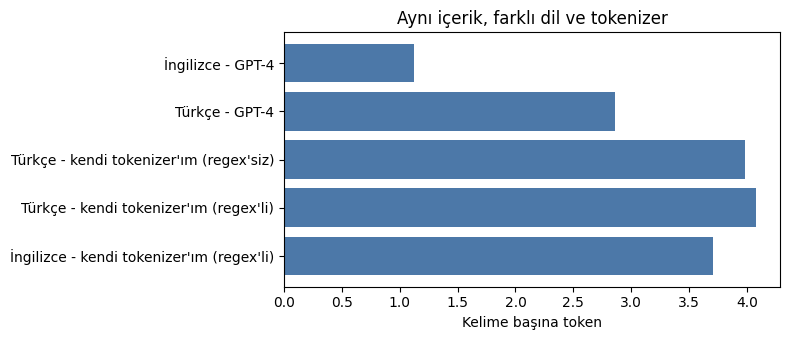

In [19]:
def gpt4_parcalar(s):
    return [gpt4.decode_single_token_bytes(t).decode("utf-8", errors="replace") for t in gpt4.encode(s)]

cift = [("kütüphaneye", "to the library"), ("şehirlerinin", "of their cities"),
        ("arkadaşlarımızla", "with our friends"), ("gidemeyeceğiz", "we will not be able to go")]
satirlar = []
for tr, en in cift:
    p_tr, p_en = gpt4_parcalar(" " + tr), gpt4_parcalar(" " + en)
    satirlar.append({"Türkçe (1 kelime)": tr, "Türkçe parçalar": " | ".join(goster(x) for x in p_tr), "Token (TR)": len(p_tr),
                     "İngilizce karşılığı": en, "İngilizce parçalar": " | ".join(goster(x) for x in p_en), "Token (EN)": len(p_en)})
df_kelime = pd.DataFrame(satirlar)
print("Bir Türkçe kelime ile İngilizce karşılığı (GPT-4)")
display(df_kelime.style.hide(axis="index"))

plt.figure(figsize=(8, 3.5))
plt.barh(df_g5["Metin / Tokenizer"], df_g5["Token / kelime"], color="#4c78a8")
plt.gca().invert_yaxis()
plt.xlabel("Kelime başına token")
plt.title("Aynı içerik, farklı dil ve tokenizer")
plt.tight_layout(); plt.show()

**Nasıl okunur?**
- **Token / kelime** sütunu tek başına yanıltabilir: Türkçe bir cümlede kelime sayısı az, kelimeler uzundur. Hem bu sütuna hem **toplam token** sayısına bak.
- GPT-4'ün Türkçe paragrafı İngilizceden fazla token ile yazması beklenir, çünkü tokenizer'ın eğitim verisi ağırlıklı İngilizce; Türkçe ekler (`-lar`, `-ımız`, `-la`) sözlükte az yer tutar ve kelimeler küçük parçalara bölünür. Sayıların bu beklentiyi doğrulayıp doğrulamadığını tabloda kendin kontrol et.
- **Kendi tokenizer'ımız** yalnızca birkaç yüz bin karakterlik Türkçe romanla ve küçük bir vocab ile eğitildi: Türkçe paragrafta GPT-4 ile yarışabilir mi yoksa daha mı zayıf, tablodan oku. İngilizce metinde ise çok az birleştirme uygulanır; `Byte / token` değerinin Türkçedekinden düşük çıkıp çıkmadığına bak.

## Mailin soruları ve yanıtlar

### Görev 1: Hangi harfler 1 byte, hangileri 2 byte? Kod noktaları neden doğrudan vocab olmaz?

Görev 1'deki tabloda: `a e i l n r` gibi **ASCII harfler 1 byte**; `ç ğ ı ö ş ü İ` gibi **Türkçe'ye özgü harfler 2 byte** tutuyor. Aynı cümlede karakter sayısı byte sayısından küçük çıkar. Kod noktalarını doğrudan vocab yapmak kötüdür çünkü: (1) vocab yüz binlerce satır olur ve çoğu satır bizim metnimizde hiç geçmez, yani hiç eğitilmez; (2) Unicode standardı yeni karakterlerle büyümeye devam eder, sabit bir sözlük sağlamaz; (3) çok büyük embedding tablosu ve çıkış katmanı hesaplamayı pahalılaştırır. Ham byte'lar ise vocab'ı 256'ya indirir ama diziyi uzatır; BPE ikisinin arasında bir denge kurar.

### Görev 2: İlk 20 birleştirmede hangi harf grupları önce birleşiyor? Sıkıştırma oranı kaç?

Cevap Görev 2'deki iki tabloda: ilk 20 birleştirme listesi ve "Sıkıştırma oranı vocab büyüdükçe" tablosu. Sıkıştırma oranı = byte sayısı / token sayısı; vocab büyüdükçe artar ama eğri düzleşir.

### Görev 3: Geçersiz UTF-8 token dizisinde `decode` ne yapmalı, neden?

`errors="replace"` kullanmalı: bozuk byte dizisini `�` ile değiştirip devam eder. Çünkü dil modelinin ürettiği token dizisi geçerli UTF-8 olmak zorunda değildir (ör. çok byte'lı bir karakterin yalnızca devam byte'ı, `128` gibi) ve `strict` modda program hata verip durur. Görev 3'teki tabloda hem hatayı hem `�` çıktısını görüyoruz.

### Görev 4: Desen Türkçede ne yapıyor?

`\p{L}` Türkçe harfleri de harf saydığı için kelimeler ortadan bölünmüyor; rakamlar 3'lü gruplanıyor; noktalama kelimeden ayrılıyor. Ama desen İngilizce kısaltmalar için `'s 'd 'm 't 'll 've 're` kalıplarını ayırıyor ve bunlar Türkçedeki kesme işaretli eklerle çakışabiliyor: `Ankara'dan` → `Ankara` + `'d` + `an`, `İstanbul'da` → `İstanbul` + `'d` + `a`; ama `Ankara'ya` → `Ankara` + `'ya` (tek parça). Yani desen Türkçe eki **ilk harfine göre** farklı bölüyor; bu istenmeyen bir tutarsızlık. Regex'li eğitimde birleştirmeler bu kutuların dışına çıkamadığı için kelime + noktalama/boşluk karışımı token'lar kalmıyor; sıkıştırma ise bu veride neredeyse aynı kalıyor.

### Görev 5: Türkçenin eklemeli yapısı token sayısını nasıl etkiliyor?

Türkçe kelime kök + ek + ek şeklinde uzar; tek bir Türkçe kelime İngilizcede birkaç kelimeye denk gelir. Tokenizer'ın sözlüğü ağırlıklı İngilizce metinle kurulduğu için Türkçe ekler hazır parça olarak az bulunur, kelimeler küçük parçalara bölünür ve aynı anlam daha çok token tutar. Sayılar Görev 5 tablosunda.

## Özet

1. **Byte'lar:** Türkçe harfler 2 byte; kod noktası vocab'ı büyük ve kırılgan, ham byte vocab'ı küçük ama dizi uzun.
2. **BPE:** Say → birleştir → tekrarla. Vocab = 256 + birleştirme sayısı. Sıkıştırma vocab ile artar, eğri düzleşir.
3. **encode / decode:** İkisi birbirinin tersi; `decode(encode(x)) == x`. Geçersiz UTF-8 için `errors="replace"`.
4. **Regex:** Metni kutulara ayırır, BPE kutu içinde çalışır. İngilizce için yazıldığından Türkçe kesme işaretli eklerde tutarsız davranır.
5. **Türkçe vs İngilizce:** Eklemeli yapı + İngilizce ağırlıklı sözlük = Türkçe için daha çok token.